In [103]:
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
import pandas as pd

In [104]:
data = fetch_california_housing(as_frame=True)

In [105]:
data

{'data':        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
 0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
 1      8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
 2      7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
 3      5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
 4      3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
 ...       ...       ...       ...        ...         ...       ...       ...   
 20635  1.5603      25.0  5.045455   1.133333       845.0  2.560606     39.48   
 20636  2.5568      18.0  6.114035   1.315789       356.0  3.122807     39.49   
 20637  1.7000      17.0  5.205543   1.120092      1007.0  2.325635     39.43   
 20638  1.8672      18.0  5.329513   1.171920       741.0  2.123209     39.43   
 20639  2.3886      16.0  5.254717   1.162264      1387.0  2.616981     39.37   
 
        Longitude 

In [106]:
df = data.frame

In [107]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [108]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [109]:
target = df['MedHouseVal']

In [110]:
target

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

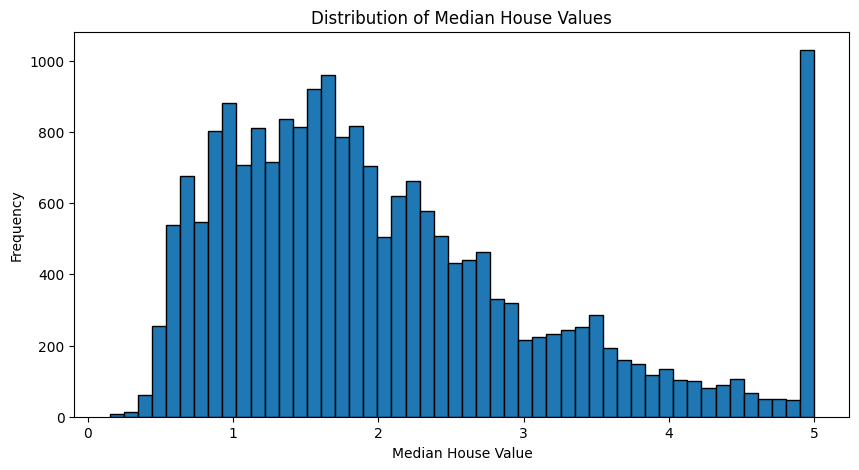

In [111]:
target.plot(kind='hist', bins=50, figsize=(10, 5), edgecolor='black')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.title('Distribution of Median House Values')
plt.show()

In [112]:
corr_matrix = df.corr()

In [113]:
corr_matrix['MedHouseVal']

MedInc         0.688075
HouseAge       0.105623
AveRooms       0.151948
AveBedrms     -0.046701
Population    -0.024650
AveOccup      -0.023737
Latitude      -0.144160
Longitude     -0.045967
MedHouseVal    1.000000
Name: MedHouseVal, dtype: float64

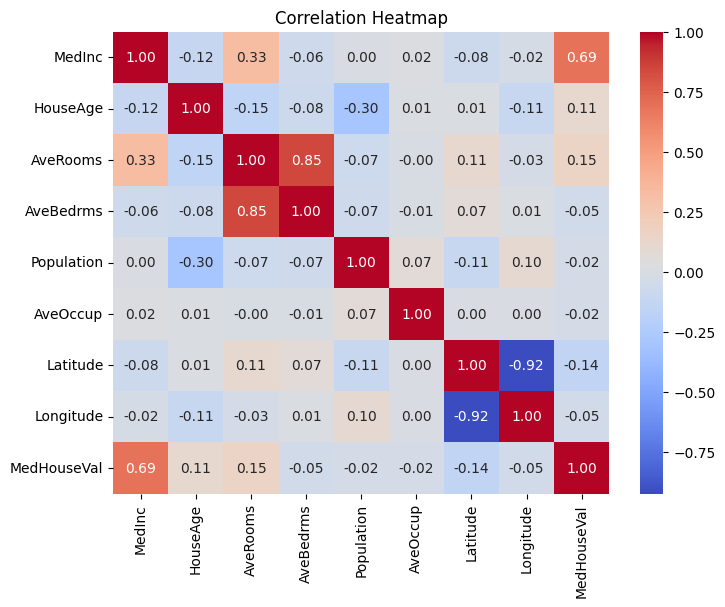

In [114]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
);

plt.title('Correlation Heatmap');
plt.show()

In [115]:
X = df.drop('MedHouseVal', axis=1)

In [116]:
y = df['MedHouseVal']

In [117]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

In [118]:
model = DecisionTreeRegressor(random_state=123)

In [119]:
model

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,123
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [120]:
model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,123
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [121]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

In [122]:
train_mae = mean_absolute_error(y_train, train_predictions)
train_mse = mean_squared_error(y_train, train_predictions)
train_rmse = root_mean_squared_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)

test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = root_mean_squared_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

In [123]:
print(train_mae, '\n', test_mae)

4.125683429687476e-17 
 0.46352322916666666


In [124]:
print(train_mse, '\n', test_mse)

9.234908731784253e-32 
 0.5318829892632995


In [125]:
print(train_rmse, '\n', test_rmse)

3.0388992631846574e-16 
 0.7293030846385469


In [126]:
print(train_r2, '\n', test_r2)

1.0 
 0.6000320873754088


In [127]:
results = []

for max_depth in [2, 3, 5, 10, 15, None]:
    for min_samples_split in [2, 5, 10, 20]:
        for min_samples_leaf in [1, 2, 5, 10]:
            for max_features in [None, 'sqrt', 'log2']:

                model = DecisionTreeRegressor(
                    max_depth=max_depth,
                    min_samples_split=min_samples_split,
                    min_samples_leaf=min_samples_leaf,
                    max_features=max_features,
                    random_state=42
                )

                model.fit(X_train, y_train)

                train_predictions = model.predict(X_train)
                test_predictions = model.predict(X_test)

                results.append({
                    'max_depth': max_depth,
                    'min_samples_split': min_samples_split,
                    'min_samples_leaf': min_samples_leaf,
                    'max_features': max_features,

                    'train_mae': mean_absolute_error(y_train, train_predictions),
                    'test_mae': mean_absolute_error(y_test, test_predictions),

                    'train_mse': mean_squared_error(y_train, train_predictions),
                    'test_mse': mean_squared_error(y_test, test_predictions),

                    'train_rmse': root_mean_squared_error(y_train, train_predictions),
                    'test_rmse': root_mean_squared_error(y_test, test_predictions),

                    'train_r2': r2_score(y_train, train_predictions),
                    'test_r2': r2_score(y_test, test_predictions)
                })

results_df = pd.DataFrame(results)


In [128]:
results_df.sort_values(by='test_r2', ascending=False).head(10)

,max_depth,min_samples_split,min_samples_leaf,max_features,train_mae,test_mae,train_mse,test_mse,train_rmse,test_rmse,train_r2,test_r2
191,10.0,20,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
155,10.0,2,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
167,10.0,5,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
179,10.0,10,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
278,NaN,20,1,log2,0.233524,0.381753,0.131284,0.338491,0.362331,0.581800,0.901437,0.745460
251,NaN,2,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
275,NaN,10,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
287,NaN,20,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
263,NaN,5,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
203,15.0,2,10,log2,0.316126,0.400858,0.223184,0.350717,0.472424,0.592214,0.832442,0.736266


In [130]:
results_df.sort_values(by='test_rmse',ascending=True).head(10)

,max_depth,min_samples_split,min_samples_leaf,max_features,train_mae,test_mae,train_mse,test_mse,train_rmse,test_rmse,train_r2,test_r2
167,10.0,5,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
179,10.0,10,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
191,10.0,20,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
155,10.0,2,10,log2,0.351367,0.395656,0.264955,0.335444,0.514738,0.579176,0.801081,0.747751
278,NaN,20,1,log2,0.233524,0.381753,0.131284,0.338491,0.362331,0.581800,0.901437,0.745460
263,NaN,5,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
275,NaN,10,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
251,NaN,2,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
287,NaN,20,10,log2,0.305660,0.393011,0.212929,0.348077,0.461443,0.589981,0.840141,0.738251
203,15.0,2,10,log2,0.316126,0.400858,0.223184,0.350717,0.472424,0.592214,0.832442,0.736266


In [131]:
results_df['r2_gap'] = (
    results_df['train_r2'] - results_df['test_r2']
)